# Kostenorientierte Klassifikation von Maschinenausfällen

**Gruppenarbeit Classification · Business Intelligence · WiSe 2026/27**  
Technische Hochschule Mannheim · Gruppe: [Gruppenname] · Mitglieder: [Jannika Julia Heckmann, Felix Bauer, Anita Kopp, Jason Neufeld]

Ziel ist die Vorhersage von Maschinenfehlschlägen unter der Kostenfunktion **FP + 6 × FN**. Verglichen werden k-Nearest Neighbors, Entscheidungsbäume, Naive Bayes, eine Support Vector Machine, Random Forest und Boosting. Als weiterer Kandidat dient das bisherige Hybridmodell aus physikalischen Regeln und Verschleißlogistik.

**Reproduktion.** Das Notebook enthält den vollständigen Modellcode und verwendet die bereitgestellten Dateien modeling.csv und challenge.csv. Die Konfiguration und der Gruppenname für den CSV-Export stehen in der ersten Codezelle. Für die Ausführung werden NumPy, pandas, scikit-learn und Matplotlib benötigt.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

GRUPPENNAME = "GRUPPENNAME"
DATENORDNER = Path(".") 
if not (DATENORDNER / "modeling.csv").is_file():
    DATENORDNER = Path.home() / "Downloads"
AUSGABEORDNER = Path("results")

TARGET = "Machine failure"
FEATURES = ["Type", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
TYP = {"L": 0, "M": 1, "H": 2}
KOSTEN_FN = 6
SCHWELLE = 1 / (1 + KOSTEN_FN)
SEEDS = (2006, 2026, 2007, 888, 1024)

## 1 · Explorative Datenanalyse

Der beschriftete Datensatz umfasst **8.000 Produktionsvorgänge**, davon **271 Ausfälle (3,39 %)**. Geprüft werden das Eingabeschema, die Gültigkeit der Sensorwerte, die Zielklassen und doppelte Merkmalszeilen. Die folgende Auswertung beschreibt die Ausfallhäufigkeit nach Produktvariante und die Verteilung der numerischen Merkmale. Extreme Messwerte bleiben als potenziell relevante Ausfallsignale erhalten.

In [2]:
def csv_lesen(pfad, mit_labels=False):
    if not pfad.is_file():
        raise FileNotFoundError(f"{pfad} fehlt. Prüfe DATENORDNER in der ersten Zelle.")
    daten = pd.read_csv(pfad, float_precision="round_trip")
    erwartet = FEATURES + ([TARGET] if mit_labels else [])
    if daten.empty or set(daten.columns) != set(erwartet):
        raise ValueError(f"{pfad}: Erwartete Spalten: {erwartet}")
    if not daten["Type"].isin(TYP).all() or not np.isfinite(daten[FEATURES[1:]].to_numpy(float)).all():
        raise ValueError(f"{pfad}: Ungültige Messwerte oder Produktvarianten.")
    if mit_labels and set(daten[TARGET].unique()) != {0, 1}:
        raise ValueError(f"{pfad}: Die Zielspalte muss beide Klassen 0 und 1 enthalten.")
    return daten

daten = csv_lesen(DATENORDNER / "modeling.csv", mit_labels=True)
X, y = daten[FEATURES], daten[TARGET].to_numpy(dtype=int)
print(f"{len(y)} Vorgänge | {y.sum()} Ausfälle ({y.mean():.2%}) | {X.duplicated().sum()} doppelte Merkmalszeilen")
varianten = daten.groupby("Type")[TARGET].agg(Vorgänge="size", Ausfälle="sum")
display(varianten.assign(Ausfallquote_Prozent=100 * varianten["Ausfälle"] / varianten["Vorgänge"]).round(2))
display(X[FEATURES[1:]].describe().round(2))

8000 Vorgänge | 271 Ausfälle (3.39%) | 0 doppelte Merkmalszeilen


,Vorgänge,Ausfälle,Ausfallquote_Prozent
Type,,,
H,795,18,2.26
L,4808,184,3.83
M,2397,69,2.88


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,8000.00,8000.00,8000.00,8000.00,8000.00
mean,300.00,310.00,1538.33,40.00,107.84
std,1.99,1.48,178.48,9.95,63.65
min,295.30,305.70,1181.00,3.80,0.00
25%,298.30,308.80,1423.00,33.20,53.00
50%,300.10,310.10,1503.00,40.10,108.00
75%,301.50,311.10,1611.00,46.70,162.00
max,304.50,313.80,2886.00,76.60,253.00


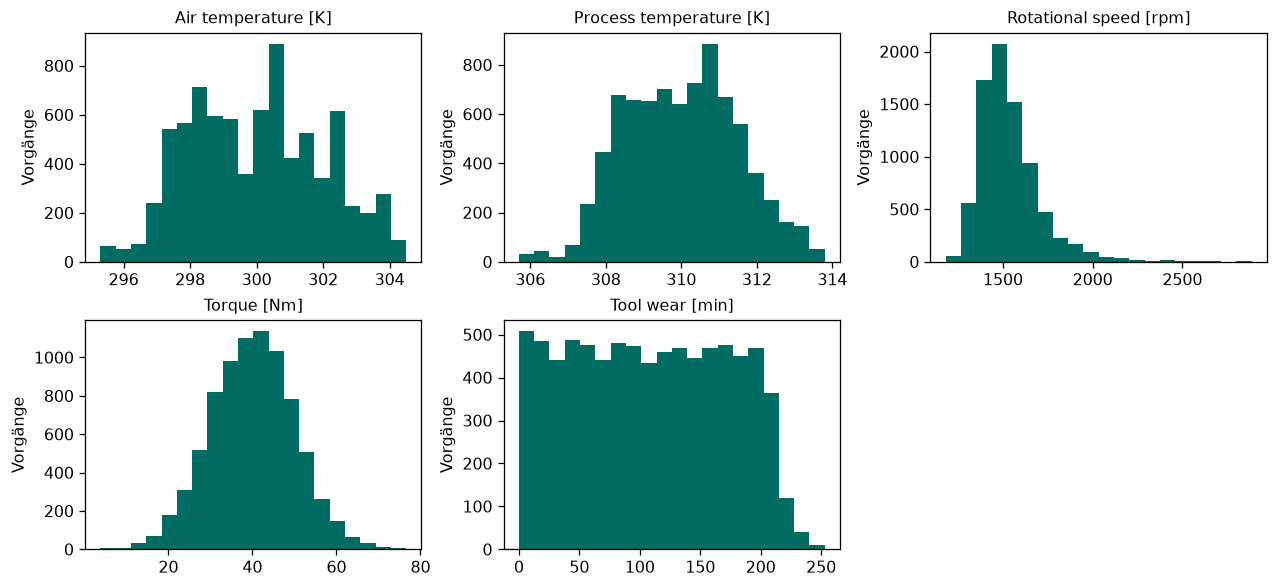

In [3]:
try:
    from matplotlib.figure import Figure
except ModuleNotFoundError as error:
    if error.name != "matplotlib":
        raise
    Figure = None

def diagramm_anzeigen(fig):
    from io import BytesIO
    from IPython.display import Image

    bild = BytesIO()
    fig.savefig(bild, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=bild.getvalue()))

if Figure is None:
    print("Für neu gerenderte Diagramme: %pip install matplotlib. Die Tabellen bleiben verfügbar.")
else:
    fig = Figure(figsize=(11, 5), layout="constrained")
    axes = fig.subplots(2, 3)
    for ax, spalte in zip(axes.flat, FEATURES[1:]):
        ax.hist(daten[spalte], bins=20, color="#006C62")
        ax.set_title(spalte, fontsize=10)
        ax.set_ylabel("Vorgänge")
    axes.flat[-1].set_visible(False)
    diagramm_anzeigen(fig)


## 2 · Trennung von Training, Validierung und Prüfung

Alle Kandidaten werden auf denselben fünf stratifizierten 5-Fold-Aufteilungen geprüft. Die Vorlesungsmodelle erhalten innerhalb jeder äußeren Trainingsfalte eine **dreifache Kreuzvalidierung**. An deren Vorhersagen wird die Alarmschwelle festgelegt. Die äußere Prüffalte bleibt davon getrennt. Bei kNN und Entscheidungsbaum gibt es je zwei vorab festgelegte Varianten.

Das Hybridmodell behält seine bisherige Schwelle 1/7. Zusätzlich bewerten wir eine Auswahlstrategie, die zwischen den Vorlesungskandidaten nur anhand der inneren Kosten entscheidet. Die Aufteilungen verwenden dieselbe Kohorte, auf der die bisherige Modellentwicklung erfolgte.

In [4]:
def falten(seed):
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y)

train, pruefung = next(falten(SEEDS[0]))
print(f"Beispielfalte: {len(train)} Vorgänge im Training, {len(pruefung)} in der Prüfung")

Beispielfalte: 6400 Vorgänge im Training, 1600 in der Prüfung


## 3 · Merkmalsaufbereitung

Drei physikalisch motivierte Merkmale ergänzen die Sensorwerte: die mechanische Leistung $P=M\,2\pi n/60$, der Temperaturabstand zwischen Prozess und Umgebung sowie das Produkt aus Werkzeugstandzeit und Drehmoment als Belastungsindikator. Für die Kühlungsregel wird der Temperaturabstand gemeinsam mit der Drehzahl ausgewertet. Die Produktvarianten L, M und H gehen als geordnete Stufen in das Modell ein.

In [5]:
def merkmale(frame):
    drehzahl = frame["Rotational speed [rpm]"].to_numpy(float)
    moment = frame["Torque [Nm]"].to_numpy(float)
    standzeit = frame["Tool wear [min]"].to_numpy(float)
    abstand = frame["Process temperature [K]"].to_numpy(float) - frame["Air temperature [K]"].to_numpy(float)
    leistung = drehzahl * moment * (2 * np.pi / 60)
    typ = frame["Type"].map(TYP).to_numpy()
    return leistung, abstand, drehzahl, standzeit * moment, typ

In [6]:
def tabellenmerkmale(frame):
    # Dieselben Rohwerte und physikalischen Merkmale für alle Vorlesungsmodelle.
    result = frame[FEATURES[1:]].copy()
    leistung, abstand, _, last, _ = merkmale(frame)
    result["Temperaturabstand [K]"] = abstand
    result["Leistung [W]"] = leistung
    result["Verschleißlast [min × Nm]"] = last
    # Feste Kategorien sichern bei jedem Teilfit dieselben Spalten.
    for typ in ("L", "M", "H"):
        result[f"Type_{typ}"] = (frame["Type"] == typ).astype(int)
    return result

modell_merkmale = tabellenmerkmale(X)
display(modell_merkmale.head(3).round(2))

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperaturabstand [K],Leistung [W],Verschleißlast [min × Nm],Type_L,Type_M,Type_H
0,297.3,308.1,1763,28.4,54,10.8,5243.23,1533.6,1,0,0
1,301.7,310.6,1545,42.1,68,8.9,6811.44,2862.8,1,0,0
2,300.5,309.9,1397,45.9,210,9.4,6714.87,9639.0,0,0,1


## 4 · Klassifikationsverfahren

kNN und SVM verwenden eine anhand der Trainingsdaten gelernte Standardisierung. Der kleine Entscheidungsbaum dient zusätzlich der Interpretation. Random Forest und Histogram Gradient Boosting vertreten Ensemble-Verfahren. Gaussian Naive Bayes ergänzt einen probabilistischen Basisklassifikator.

Der Regelkern aus V2 ist der regelbasierte Kandidat. Seine Zusammensetzung mit der Verschleißlogistik bleibt separat erkennbar. Die Vorlesungsmodelle verwenden dieselben Merkmale und sind im Code mit MODELLBEGINN markiert.

In [7]:
# MODELLBEGINN: k-Nearest Neighbors. Skalierung nur auf der Trainingsfalte lernen.
modelle = {
    "kNN k=5": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "kNN k=15": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}

# MODELLBEGINN: Entscheidungsbäume. Die kleine Variante wird später dargestellt.
modelle.update({
    "Baum Tiefe 3": DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=57),
    "Baum Tiefe 6": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=57),
})

# MODELLBEGINN: Random Forest als Ensemble von Bäumen.
modelle["Random Forest"] = RandomForestClassifier(
    n_estimators=120, min_samples_leaf=2, random_state=57, n_jobs=2,
)

# MODELLBEGINN: Boosting durch schrittweises Ergänzen kleiner Bäume.
modelle["Gradient Boosting"] = HistGradientBoostingClassifier(
    max_iter=120, max_depth=3, min_samples_leaf=20, random_state=57,
)

# MODELLBEGINN: Gaussian Naive Bayes.
modelle["Naive Bayes"] = GaussianNB()

# MODELLBEGINN: SVM mit Wahrscheinlichkeitskalibrierung innerhalb der Trainingsdaten.
# Die Skalierung wird auch in jeder Kalibrierungsfalte separat gelernt.
modelle["SVM"] = CalibratedClassifierCV(
    make_pipeline(StandardScaler(), SVC(C=1.0)),
    method="sigmoid",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=57),
    ensemble=False,
)

In [8]:
def schnitt(von, bis, raster):
    for einheit in raster:
        kandidat = (np.floor(von / einheit) + 1) * einheit
        if von < kandidat <= bis:
            return kandidat
    return max(von + (bis - von) / 2, np.nextafter(von, bis))

def untergrenze(werte, ziel, raster):
    normal = werte[ziel == 0]
    erster_normaler = normal.min() if len(normal) else np.inf
    treffer = werte[(ziel == 1) & (werte < erster_normaler)]
    if not len(treffer):
        return -np.inf, 0
    grenze = schnitt(treffer.max(), erster_normaler, raster) if len(normal) else np.inf
    return grenze, len(treffer)

def kuehlgrenzen(abstand, drehzahl, ziel):
    kandidaten = np.unique(abstand)
    bestes_paar, beste_treffer = (-np.inf, -np.inf), 0
    for i, wert in enumerate(kandidaten):
        innen = abstand <= wert
        rpm, treffer = untergrenze(drehzahl[innen], ziel[innen], (10, 1))
        if treffer > beste_treffer:
            naechster = kandidaten[i + 1] if i + 1 < len(kandidaten) else np.inf
            bestes_paar, beste_treffer = (schnitt(wert, naechster, (0.1,)), rpm), treffer
    return bestes_paar

def belastungsgrenzen(last, typ, ziel):
    abstaende = sorted(range(0, 3001, 100), key=lambda a: (a % 1000 != 0, a % 500 != 0, a))
    beste_treffer = -1
    for abstand in abstaende:
        grenze, treffer = untergrenze(abstand * typ - last, ziel, (1000, 100, 10))
        if treffer > beste_treffer:
            grenzen, beste_treffer = -grenze + abstand * np.arange(len(TYP)), treffer
    return grenzen

In [9]:
# MODELLBEGINN: Physikalische Regeln für Leistung, Kühlung und Werkzeugbelastung.
def regeln_lernen(frame, ziel):
    leistung, abstand, drehzahl, last, typ = merkmale(frame)
    kuehlalarm = np.zeros(len(ziel), dtype=bool)
    lastalarm = np.zeros(len(ziel), dtype=bool)
    raster = (1000, 100, 50, 10)
    # Drei Durchläufe stimmen jede Grenze auf den Rest ohne die anderen Alarme ab.
    for _ in range(3):
        rest = ~(kuehlalarm | lastalarm)
        tief, _ = untergrenze(leistung[rest], ziel[rest], raster)
        negativ_hoch, _ = untergrenze(-leistung[rest], ziel[rest], raster)
        hoch = -negativ_hoch
        leistung_alarm = (leistung < tief) | (leistung > hoch)
        rest = ~(leistung_alarm | lastalarm)
        delta, rpm = kuehlgrenzen(abstand[rest], drehzahl[rest], ziel[rest])
        kuehlalarm = (abstand < delta) & (drehzahl < rpm)
        rest = ~(leistung_alarm | kuehlalarm)
        lastgrenzen = belastungsgrenzen(last[rest], typ[rest], ziel[rest])
        lastalarm = last > lastgrenzen[typ]
    return tief, hoch, delta, rpm, lastgrenzen

def regelalarm(frame, grenzen):
    leistung, abstand, drehzahl, last, typ = merkmale(frame)
    tief, hoch, delta, rpm, lastgrenzen = grenzen
    return ((leistung < tief) | (leistung > hoch)
            | ((abstand < delta) & (drehzahl < rpm)) | (last > lastgrenzen[typ]))

## 5 · Verschleißmodell und Alarmschwelle

Die logistische Regression (L2-Regularisierung, $C=1$) wird auf den Trainingsvorgängen ohne Regelalarm angepasst. Ihre Merkmale sind die Produktstufe und die Standzeit oberhalb des ersten Zehn-Minuten-Bands mit mindestens 30 Vorgängen und mindestens 2 % Ausfällen. Beide Merkmale werden anhand der Trainingsdaten standardisiert.

Bei geschätztem Ausfallrisiko $p$ betragen die erwarteten Kosten der Freigabe $6p$ und die des Alarms $1-p$. Daher wird die Schwelle der zweiten Stufe auf **$1/7$** gesetzt. Das Hybridmodell alarmiert, sobald eine physikalische Regel oder die Verschleißstufe einen Alarm auslöst.

In [10]:
def verschleissmerkmale(frame, beginn):
    standzeit = frame["Tool wear [min]"].to_numpy(float)
    typ = frame["Type"].map(TYP).to_numpy()
    return np.column_stack((np.maximum(standzeit - beginn, 0), typ))

# MODELLBEGINN: Hybrid aus Regelalarm und logistischer Regression.
def hybrid_trainieren(frame, ziel):
    grenzen = regeln_lernen(frame, ziel)
    rest = ~regelalarm(frame, grenzen)
    band = (frame.loc[rest, "Tool wear [min]"] // 10) * 10
    statistik = pd.Series(ziel[rest], index=band.index).groupby(band).agg(["size", "mean"])
    # Erstes Zehn-Minuten-Band mit mindestens 30 Fällen und 2 % Ausfällen.
    passend = statistik[(statistik["size"] >= 30) & (statistik["mean"] >= 0.02)]
    if passend.empty or np.unique(ziel[rest]).size < 2:
        return grenzen, None, None
    beginn = float(passend.index.min())
    logistik = make_pipeline(StandardScaler(), LogisticRegression(C=1.0))
    logistik.fit(verschleissmerkmale(frame.loc[rest], beginn), ziel[rest])
    return grenzen, beginn, logistik

def vorhersagen(frame, modell):
    grenzen, beginn, logistik = modell
    kern = regelalarm(frame, grenzen)
    if logistik is None:
        return kern.astype(int), kern.astype(int)
    score = logistik.predict_proba(verschleissmerkmale(frame, beginn))[:, 1]
    return kern.astype(int), (kern | (score >= SCHWELLE)).astype(int)

## 6 · Modellevaluation und Vergleich

Die **Kosten FP + 6 × FN** sind die primäre Vergleichsgröße. Ergänzend berichten wir Accuracy, Error Rate, Precision, Recall, Specificity, FPR und FNR entsprechend der Vorlesung. Accuracy allein würde die Mehrheitsklasse bevorzugen. Precision wird bei fehlendem Alarm auf 0 gesetzt.

Die inneren Vorhersagen bestimmen die Schwelle der Vorlesungsmodelle. Bei gleichem Kostenminimum wird der erste Betriebspunkt mit weniger Alarmen verwendet. Die Zeile „Innere Auswahl Vorlesungsmodelle“ bewertet zusätzlich die Modellwahl anhand der inneren Kosten. Die Rangfolge der Einzelmodelle auf den äußeren Ergebnissen ist ein nachträglicher Vergleich.

In [11]:
def kennzahlen(wahr, prognose):
    tn, fp, fn, tp = confusion_matrix(wahr, prognose, labels=[0, 1]).ravel()
    return {
        "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Kosten": fp + KOSTEN_FN * fn,
        "Accuracy": (tp + tn) / len(wahr), "Error Rate": (fp + fn) / len(wahr),
        "Precision": tp / (tp + fp) if tp + fp else 0.0,
        "Recall": tp / (tp + fn), "Specificity": tn / (tn + fp),
        "FPR": fp / (tn + fp), "FNR": fn / (tp + fn),
    }

def schwelle_waehlen(ziel, score):
    # Gleiche Scores zusammenhalten und alle möglichen Betriebspunkte zählen.
    sortierung = np.argsort(-score, kind="stable")
    sortierte_scores = score[sortierung]
    enden = np.r_[np.flatnonzero(np.diff(sortierte_scores) != 0), len(score) - 1]
    aenderung = np.where(ziel[sortierung] == 1, -KOSTEN_FN, 1)
    kosten = KOSTEN_FN * ziel.sum() + np.r_[0, np.cumsum(aenderung)[enden]]
    grenzen = np.r_[np.inf, sortierte_scores[enden]]
    beste_position = int(np.argmin(kosten))
    return float(grenzen[beste_position]), int(kosten[beste_position])

ergebnisse, faltenergebnisse = [], []
with threadpool_limits(limits=2):
    for seed in SEEDS:
        namen = ["Nie Alarm", "Physikalische Regeln", "Hybrid", *modelle, "Innere Auswahl Vorlesungsmodelle"]
        prognosen_cv = {name: np.zeros_like(y) for name in namen}
        for nummer, (train, pruefung) in enumerate(falten(seed), 1):
            hybrid = hybrid_trainieren(X.iloc[train], y[train])
            kern_pred, hybrid_pred = vorhersagen(X.iloc[pruefung], hybrid)
            prognosen_cv["Physikalische Regeln"][pruefung] = kern_pred
            prognosen_cv["Hybrid"][pruefung] = hybrid_pred

            # Schwellenwahl ausschließlich aus inneren Out-of-Fold-Scores.
            innen = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed + 100 * nummer)
            splits = list(innen.split(modell_merkmale.iloc[train], y[train]))
            innere_kosten, schwellen = {}, {}
            for name, kandidat in modelle.items():
                score_innen = np.empty(len(train))
                for fit, valid in splits:
                    teilmodell = clone(kandidat).fit(modell_merkmale.iloc[train[fit]], y[train[fit]])
                    score_innen[valid] = teilmodell.predict_proba(modell_merkmale.iloc[train[valid]])[:, 1]
                grenze, kosten_innen = schwelle_waehlen(y[train], score_innen)
                innere_kosten[name], schwellen[name] = kosten_innen, grenze
                gelernt = clone(kandidat).fit(modell_merkmale.iloc[train], y[train])
                score_aussen = gelernt.predict_proba(modell_merkmale.iloc[pruefung])[:, 1]
                prognosen_cv[name][pruefung] = score_aussen >= grenze
                if seed == SEEDS[0] and nummer == 1 and name == "Baum Tiefe 3":
                    kleiner_baum = gelernt
                    baum_schwelle = grenze

            gewinner = min(innere_kosten, key=innere_kosten.get)
            prognosen_cv["Innere Auswahl Vorlesungsmodelle"][pruefung] = prognosen_cv[gewinner][pruefung]
            faltenergebnisse.append({"Seed": seed, "Falte": nummer, "Auswahl": gewinner, "Schwellen": schwellen})
        for name, prognose in prognosen_cv.items():
            ergebnisse.append({"Seed": seed, "Modell": name, **kennzahlen(y, prognose)})
        print(f"Seed {seed} abgeschlossen.")

cv = pd.DataFrame(ergebnisse)
metriken = ["Kosten", "FP", "FN", "Accuracy", "Error Rate", "Precision", "Recall", "Specificity", "FPR", "FNR"]
vergleich = cv.groupby("Modell")[metriken].mean().sort_values("Kosten", kind="stable")
prozent = ["Accuracy", "Error Rate", "Precision", "Recall", "Specificity", "FPR", "FNR"]
anzeige = vergleich.copy()
anzeige[prozent] *= 100
display(anzeige.rename(columns={name: name + " [%]" for name in prozent}).round(2))
display(cv.pivot(index="Seed", columns="Modell", values="Kosten").loc[list(SEEDS)])
erster_lauf = cv[(cv["Seed"] == SEEDS[0]) & (cv["Modell"] == "Hybrid")].iloc[0]

Seed 2006 abgeschlossen.
Seed 2026 abgeschlossen.
Seed 2007 abgeschlossen.
Seed 888 abgeschlossen.
Seed 1024 abgeschlossen.


,Kosten,FP,FN,Accuracy [%],Error Rate [%],Precision [%],Recall [%],Specificity [%],FPR [%],FNR [%]
Modell,,,,,,,,,,
Hybrid,237.6,25.2,35.4,99.24,0.76,90.34,86.94,99.67,0.33,13.06
Physikalische Regeln,252.0,0.0,42.0,99.48,0.52,100.00,84.50,100.00,0.00,15.50
Innere Auswahl Vorlesungsmodelle,301.8,42.6,43.2,98.93,1.07,84.32,84.06,99.45,0.55,15.94
Random Forest,303.4,44.2,43.2,98.91,1.09,83.84,84.06,99.43,0.57,15.94
Baum Tiefe 6,321.6,24.0,49.6,99.08,0.92,90.28,81.70,99.69,0.31,18.30
Gradient Boosting,333.0,77.4,42.6,98.50,1.50,75.03,84.28,99.00,1.00,15.72
SVM,563.8,193.0,61.8,96.82,3.19,52.07,77.20,97.50,2.50,22.80
kNN k=15,695.4,277.8,69.6,95.66,4.34,42.14,74.32,96.41,3.59,25.68
Baum Tiefe 3,768.4,6.4,127.0,98.33,1.67,95.76,53.14,99.92,0.08,46.86


Modell,Baum Tiefe 3,Baum Tiefe 6,Gradient Boosting,Hybrid,Innere Auswahl Vorlesungsmodelle,Naive Bayes,Nie Alarm,Physikalische Regeln,Random Forest,SVM,kNN k=15,kNN k=5
Seed,,,,,,,,,,,,
2006,763,309,348,240,303,933,1626,252,311,561,695,753
2026,762,329,328,237,306,928,1626,252,306,557,667,754
2007,765,304,325,242,283,919,1626,252,283,579,709,780
888,775,315,318,235,288,916,1626,252,288,562,672,777
1024,777,351,346,234,329,939,1626,252,329,560,734,806


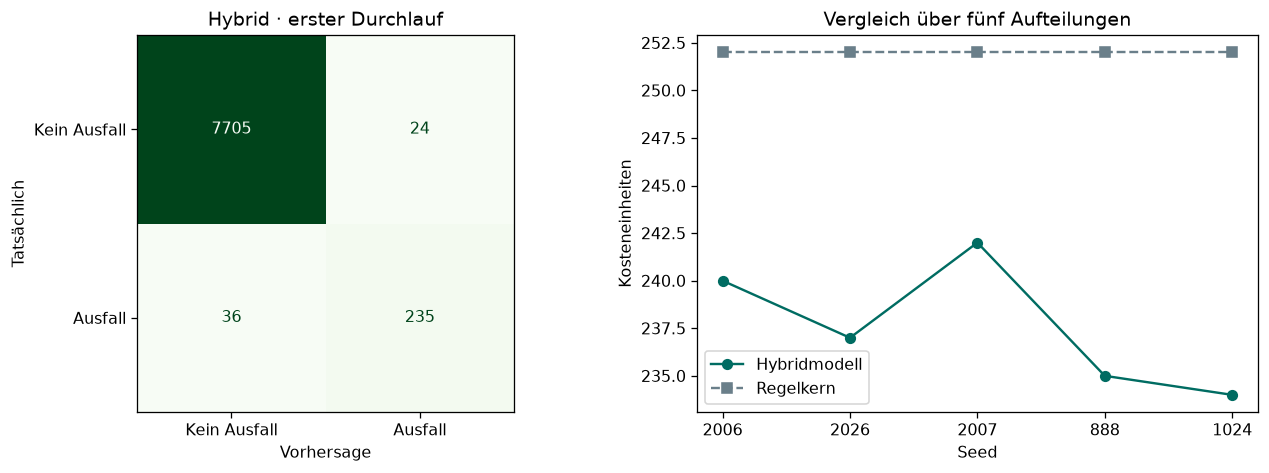

In [12]:
# Werte aus der berechneten Kreuzvalidierung übernehmen.
kosten = cv.pivot(index="Seed", columns="Modell", values="Kosten").loc[list(SEEDS)]
matrix = np.array([
    [erster_lauf["TN"], erster_lauf["FP"]],
    [erster_lauf["FN"], erster_lauf["TP"]],
])
if Figure is None:
    print("Für neu gerenderte Diagramme: %pip install matplotlib. Die Tabellen bleiben verfügbar.")
else:
    from sklearn.metrics import ConfusionMatrixDisplay

    # Links die Fehlertypen, rechts die Kostenstabilität auf denselben Seeds.
    fig = Figure(figsize=(11, 4), layout="constrained")
    axes = fig.subplots(1, 2)
    ConfusionMatrixDisplay(matrix, display_labels=["Kein Ausfall", "Ausfall"]).plot(
        ax=axes[0], colorbar=False, cmap="Greens", values_format="d"
    )
    axes[0].set(xlabel="Vorhersage", ylabel="Tatsächlich", title="Hybrid · erster Durchlauf")
    labels = [str(seed) for seed in SEEDS]
    axes[1].plot(labels, kosten["Hybrid"], "o-", color="#006C62", label="Hybridmodell")
    axes[1].plot(labels, kosten["Physikalische Regeln"], "s--", color="#6A7F8A", label="Regelkern")
    axes[1].set(xlabel="Seed", ylabel="Kosteneinheiten", title="Vergleich über fünf Aufteilungen")
    axes[1].legend()
    diagramm_anzeigen(fig)


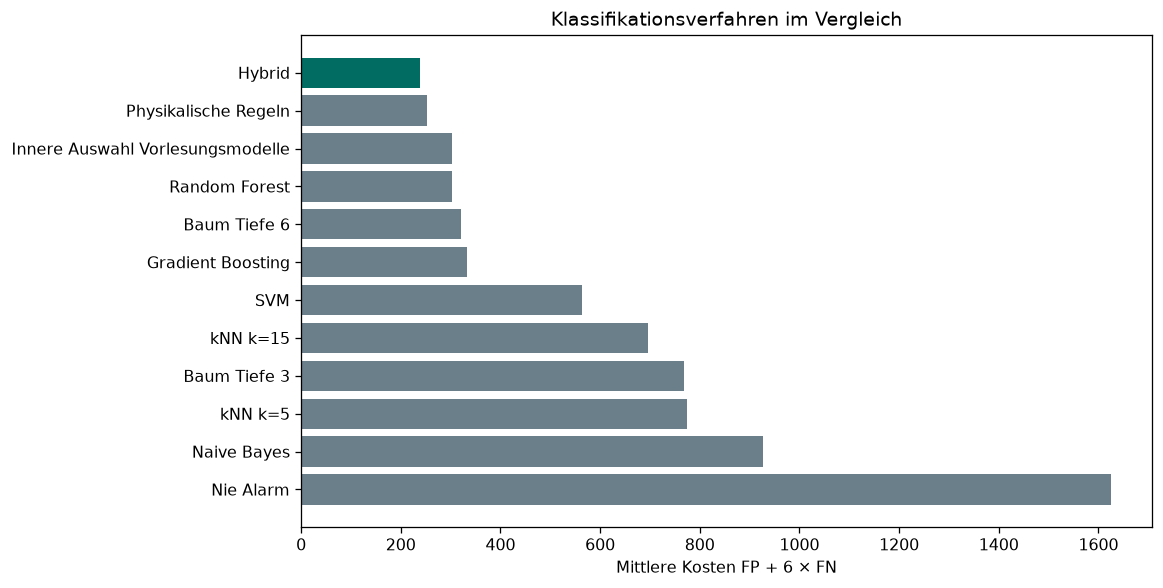

In [13]:
if Figure is not None:
    fig = Figure(figsize=(10, 5), layout="constrained")
    ax = fig.subplots()
    farben = ["#006C62" if name == "Hybrid" else "#6A7F8A" for name in vergleich.index]
    ax.barh(vergleich.index, vergleich["Kosten"], color=farben)
    ax.invert_yaxis()
    ax.set(xlabel="Mittlere Kosten FP + 6 × FN", title="Klassifikationsverfahren im Vergleich")
    diagramm_anzeigen(fig)

## 7 · Interpretation des Entscheidungsbaums und der Hybridregeln

Der kleine Entscheidungsbaum wurde auf der ersten äußeren Trainingsfalte gelernt. Seine Splits und Blätter zeigen die Merkmalsbeiträge in diesem Modell. Die Darstellung enthält alle Ebenen bis zur maximalen Tiefe 3. Die Klassenanteile sind Trainingsanteile. Die im Knoten angezeigte Klasse ist die häufigere Trainingsklasse. Der tatsächliche Alarm richtet sich nach dem Blattanteil und der darunter angegebenen, innerlich gewählten Schwelle. Anschließend werden die Hybridregeln auf allen beschrifteten Daten trainiert und separat dokumentiert.

Alarmschwelle dieses Baums aus innerer CV: 0.333


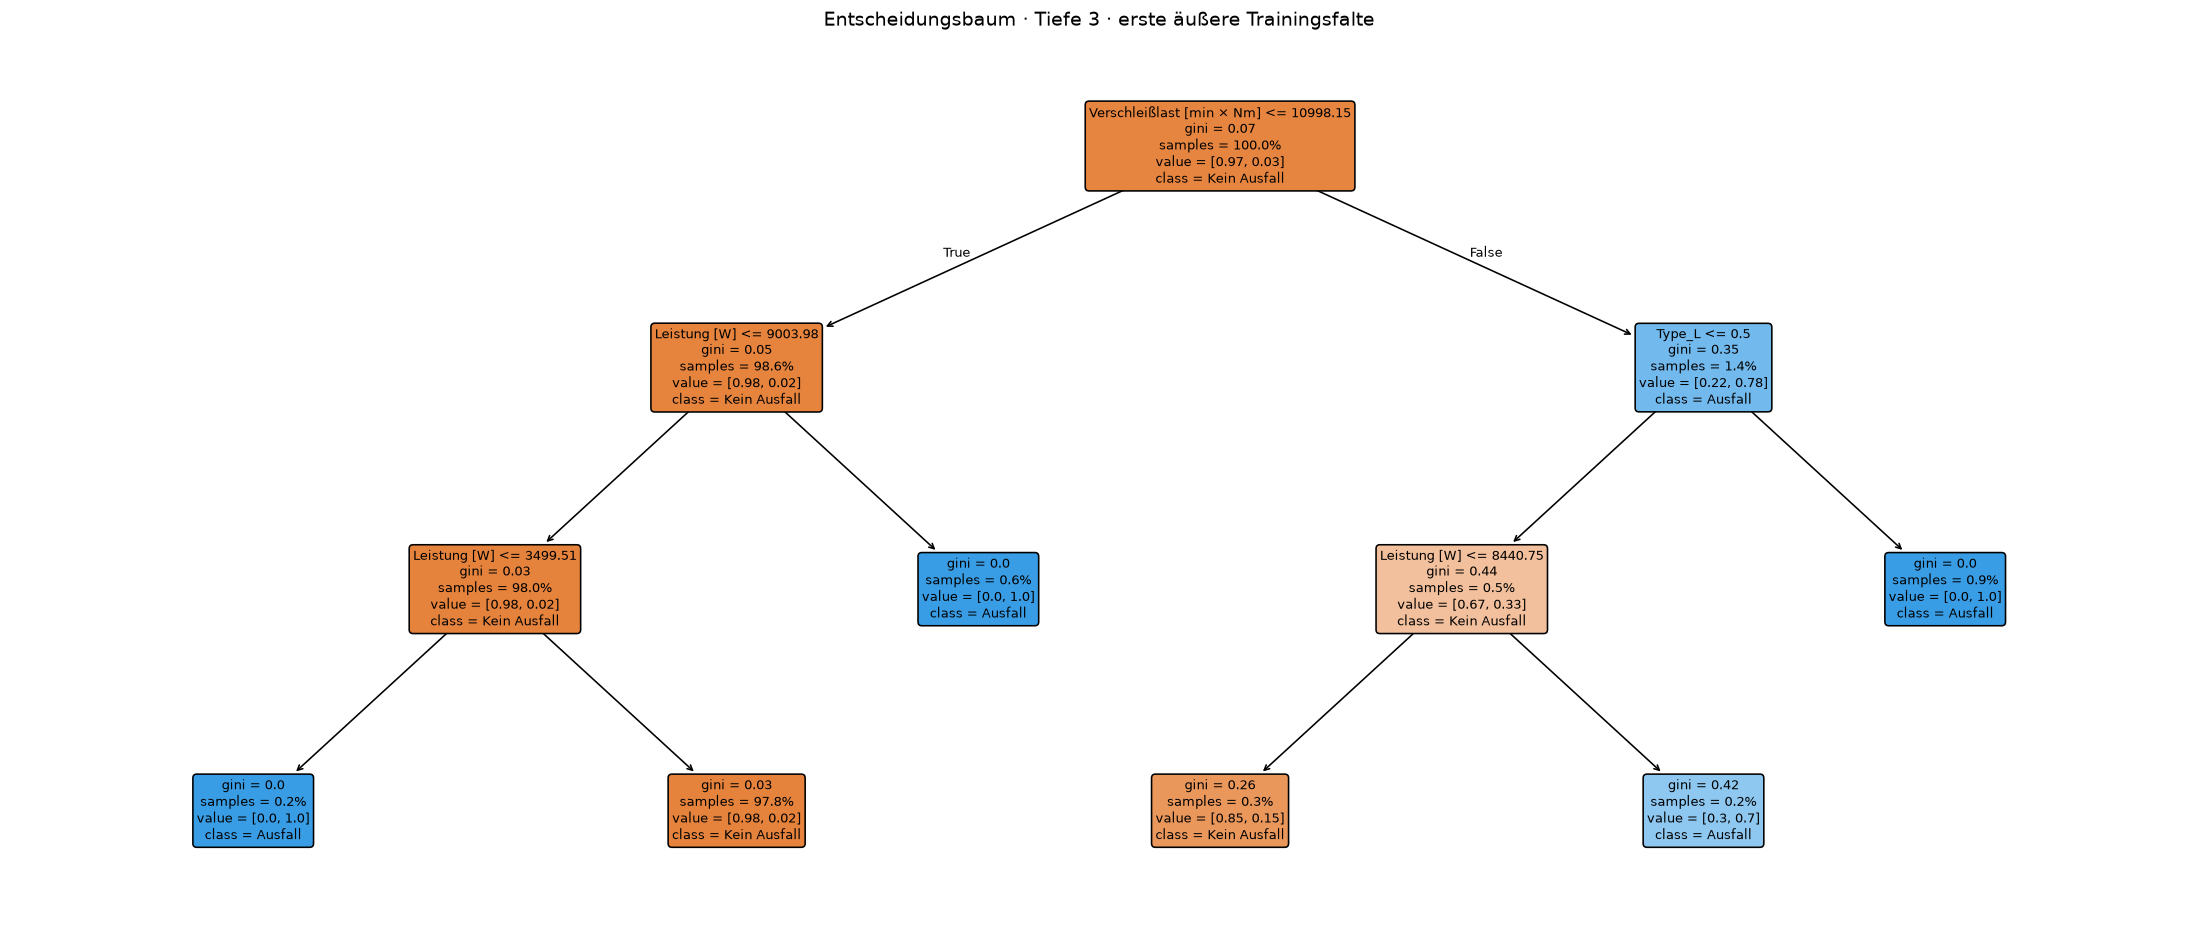

In [14]:
if Figure is not None:
    from matplotlib.backends.backend_agg import FigureCanvasAgg

    fig = Figure(figsize=(19, 8), layout="constrained")
    FigureCanvasAgg(fig)  # Stellt auch ohne grafisches Fenster einen Renderer für den Baum bereit.
    ax = fig.subplots()
    plot_tree(
        kleiner_baum, feature_names=list(modell_merkmale.columns),
        class_names=["Kein Ausfall", "Ausfall"], filled=True, rounded=True,
        proportion=True, precision=2, fontsize=8, ax=ax,
    )
    ax.set_title("Entscheidungsbaum · Tiefe 3 · erste äußere Trainingsfalte")
    diagramm_anzeigen(fig)
print(f"Alarmschwelle dieses Baums aus innerer CV: {baum_schwelle:.3f}")

In [15]:
finales_modell = hybrid_trainieren(X, y)
(tief, hoch, delta, rpm, lastgrenzen), beginn, _ = finales_modell
grenzen_anzeigen = [
    ("Leistung unter [W]", tief), ("Leistung über [W]", hoch),
    ("Kühlung: Temperaturabstand unter [K]", delta), ("Kühlung: zugleich Drehzahl unter [U/min]", rpm),
    *[(f"Belastung Typ {typ} über [min × Nm]", lastgrenzen[code]) for typ, code in TYP.items()],
    ("Beginn des Verschleißeffekts [min]", beginn),
]
display(pd.DataFrame(grenzen_anzeigen, columns=["Merkmal", "Gelernte Grenze"]).round(2))

,Merkmal,Gelernte Grenze
0,Leistung unter [W],3500.0
1,Leistung über [W],9000.0
2,Kühlung: Temperaturabstand unter [K],8.6
3,Kühlung: zugleich Drehzahl unter [U/min],1380.0
4,Belastung Typ L über [min × Nm],11000.0
5,Belastung Typ M über [min × Nm],12000.0
6,Belastung Typ H über [min × Nm],13000.0
7,Beginn des Verschleißeffekts [min],200.0


## 8 · Challenge-Prognose und Kostenschätzung

Nach Abschluss des Trainings wird challenge.csv eingelesen. Der Export enthält ausschließlich die Spalte Machine failure und hält die Eingabereihenfolge ein. Die erwarteten Gesamtkosten ergeben sich aus den mittleren Validierungskosten je Vorgang, multipliziert mit der Zahl der Challenge-Vorgänge. Die Hochrechnung setzt vergleichbare Vorgänge voraus.

In [16]:
if not re.fullmatch(r"[\w -]+", GRUPPENNAME) or not GRUPPENNAME.strip():
    raise ValueError("Bitte einen gültigen Gruppennamen in der ersten Zelle eintragen.")
challenge = csv_lesen(DATENORDNER / "challenge.csv")
_, prognosen = vorhersagen(challenge, finales_modell)
AUSGABEORDNER.mkdir(parents=True, exist_ok=True)
datei = AUSGABEORDNER / f"challenge_prediction_{GRUPPENNAME}.csv"
pd.DataFrame({TARGET: prognosen}).to_csv(datei, index=False, lineterminator="\n")
kontrolle = pd.read_csv(datei)
assert list(kontrolle.columns) == [TARGET] and np.array_equal(kontrolle[TARGET], prognosen)

kosten_mittel = cv.loc[cv["Modell"] == "Hybrid", "Kosten"].mean()
erwartete_kosten = kosten_mittel / len(y) * len(challenge)
print(f"{datei} | {len(prognosen)} Vorhersagen | {prognosen.sum()} Alarme")
print(f"Geschätzte Challenge-Kosten: {erwartete_kosten:.1f}")

results\challenge_prediction_GRUPPENNAME.csv | 2000 Vorhersagen | 63 Alarme
Geschätzte Challenge-Kosten: 59.4


## Schlussfolgerungen

Die Zusammenfassung wird aus dem ausgeführten Modellvergleich erzeugt. Der Hybrid bleibt der festgelegte Abgabekandidat aus V2. Die Vorlesungsmodelle liefern einen nachvollziehbaren Vergleich und der kleine Baum eine zusätzliche Interpretation. Eine spätere Wahl anhand der äußeren Rangliste wäre ein weiterer Entwicklungsschritt auf derselben Kohorte.

In [17]:
bestes_einzelmodell = vergleich.drop(index=["Nie Alarm", "Innere Auswahl Vorlesungsmodelle"]).index[0]
print(f"Niedrigste mittlere Kosten im Vergleich: {bestes_einzelmodell} ({vergleich.loc[bestes_einzelmodell, 'Kosten']:.1f})")
print(f"Hybrid: {vergleich.loc['Hybrid', 'Kosten']:.1f} | Regelkern: {vergleich.loc['Physikalische Regeln', 'Kosten']:.1f}")
print(f"Challenge: {len(prognosen)} Vorgänge, {prognosen.sum()} Alarme, geschätzte Kosten {erwartete_kosten:.1f}")

Niedrigste mittlere Kosten im Vergleich: Hybrid (237.6)
Hybrid: 237.6 | Regelkern: 252.0
Challenge: 2000 Vorgänge, 63 Alarme, geschätzte Kosten 59.4


## Grundlagen, Eigenbeiträge und Hilfsmittel

**Fachliche Grundlagen.** Gruppenarbeit Classification, TH Mannheim, WiSe 2026/27, insbesondere S. 4–5. Vorlesung von A. Samberg, Data Mining – Classification Part 1 (Klassifikationsverfahren) und Part 2 (Konfusionsmatrix, Gütemaße, Modellwahl und Kreuzvalidierung).

**Dokumentierte Beiträge der Gruppe.** Die Gruppe stellte Aufgabenstellung und Vorlesungsunterlagen bereit, diskutierte die Kostenrelation, hinterfragte Modellkomplexität und Verständlichkeit und gab die Ausrichtung am Vorlesungsablauf sowie den zusätzlichen Vergleich der Klassifikationsmodelle vor. Die Rückmeldungen führten zur eigenständigen Notebook-Fassung und zur V3 mit Entscheidungsbaumdarstellung.

**KI-Unterstützung.** OpenAI Codex, OpenAI, 19.11.2026. Unterstützung bei Codeentwurf und Kommentierung, Ausführung der dokumentierten Berechnungen sowie Formulierung und Überarbeitung der Notebook-Texte. Die Gruppe ergänzt vor der Abgabe ihre tatsächlich durchgeführten fachlichen Prüfungen, Interpretation der Ergebnisse und weiteren Eigenbeiträge. Die Verantwortung für die eingereichte Fassung liegt bei den Gruppenmitgliedern. Details stehen im Hilfsmittelverzeichnis.